# IS507 Heart Failure Death Prediction
**Goal:** predict whether a heart failure patient dies during follow-up (up to ~10 months), using Logistic Regression, Random Forest, and XGBoost.

**Plan:** load data → check data → split → baseline → models → tune → test fake (synthetic) data → feature importance → one final test.

## Step 1: Import libraries
**Must run this cell first.** Every cell below depends on these libraries.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     StratifiedKFold, GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42          # keeps results the same every run
pd.set_option("display.max_colwidth", None)

## Step 2: Load the data
Loading the UCI Heart Failure dataset into a table called `df`. Each row is one patient.
The last column, `DEATH_EVENT`, is what we want to predict (1 = died, 0 = survived).

In [2]:
df = pd.read_csv('~/Downloads/heart_failure_clinical_records_dataset.csv')
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


## Step 3: Check the data
Checking for missing values, duplicate rows, and how many patients survived vs died.
**Why it matters:** the data is lopsided (more survivors than deaths), and `time` only goes up to 285 days.
That is why we predict death *during follow-up* and not 1, 2, or 3 year survival.

In [3]:
print("Shape (rows, columns):", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nDeath event counts:")
print(df['DEATH_EVENT'].value_counts())
print("\nDeath event percentages:")
print((df['DEATH_EVENT'].value_counts(normalize=True) * 100).round(1))
print("\nFollow-up time (days):")
print(df['time'].describe().round(1))

Shape (rows, columns): (299, 13)
Missing values: 0
Duplicate rows: 0

Death event counts:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

Death event percentages:
DEATH_EVENT
0    67.9
1    32.1
Name: proportion, dtype: float64

Follow-up time (days):
count    299.0
mean     130.3
std       77.6
min        4.0
25%       73.0
50%      115.0
75%      203.0
max      285.0
Name: time, dtype: float64


## Step 4: Describe the variables
Summary numbers and charts for the clinical variables.
Number columns get mean, median, min, max, and standard deviation. Yes/no columns get counts and percentages.

,mean,median,min,max,std
age,60.83,60.0,40.0,95.0,11.89
creatinine_phosphokinase,581.84,250.0,23.0,7861.0,970.29
ejection_fraction,38.08,38.0,14.0,80.0,11.83
platelets,263358.03,262000.0,25100.0,850000.0,97804.24
serum_creatinine,1.39,1.1,0.5,9.4,1.03
serum_sodium,136.63,137.0,113.0,148.0,4.41
time,130.26,115.0,4.0,285.0,77.61


,count_0,count_1,percent_1
anaemia,170,129,43.1
diabetes,174,125,41.8
high_blood_pressure,194,105,35.1
sex,105,194,64.9
smoking,203,96,32.1
DEATH_EVENT,203,96,32.1


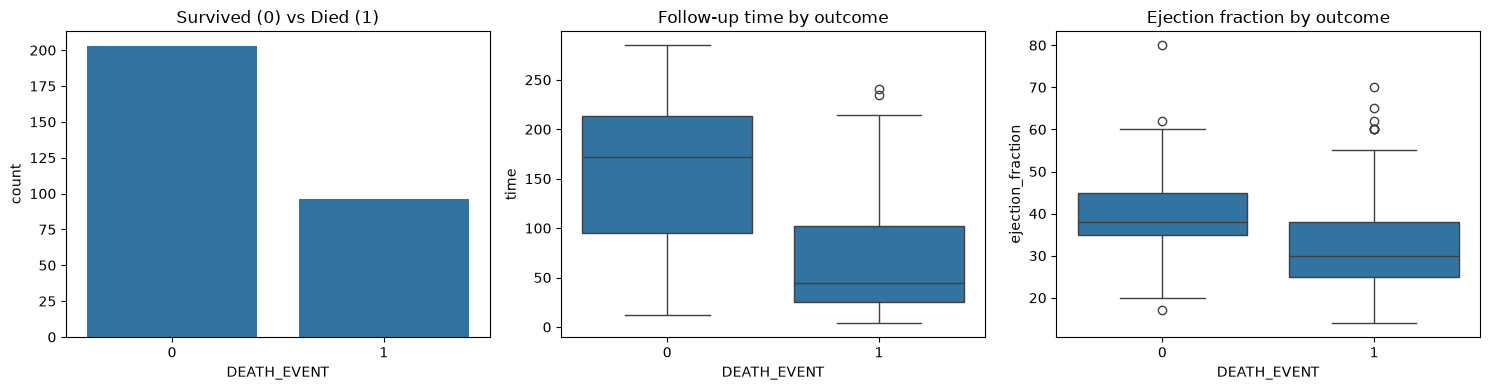

In [4]:
continuous = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets',
              'serum_creatinine', 'serum_sodium', 'time']
binary = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']

display(df[continuous].agg(['mean', 'median', 'min', 'max', 'std']).T.round(2))

counts = pd.DataFrame({c: df[c].value_counts() for c in binary}).T
counts.columns = ['count_0', 'count_1']
counts['percent_1'] = (counts['count_1'] / len(df) * 100).round(1)
display(counts)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='DEATH_EVENT', data=df, ax=ax[0])
ax[0].set_title('Survived (0) vs Died (1)')
sns.boxplot(x='DEATH_EVENT', y='time', data=df, ax=ax[1])
ax[1].set_title('Follow-up time by outcome')
sns.boxplot(x='DEATH_EVENT', y='ejection_fraction', data=df, ax=ax[2])
ax[2].set_title('Ejection fraction by outcome')
plt.tight_layout()
plt.show()

## Step 5: Split the data (train and test)
80% of the real patients go to training (239) and 20% are locked away as a test set (60).
The split keeps the same survive/die ratio in both parts. **The test set is not touched until the very last step.**

I also make two feature lists: one with `time` and one without it.
`time` is the follow-up length, which ends when a patient dies, so a doctor would not know it in advance.

In [5]:
X = df.drop(columns='DEATH_EVENT')
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training patients:", len(X_train), "| Test patients:", len(X_test))
print("Train deaths:", y_train.sum(), "| Test deaths:", y_test.sum())
print("Rows shared by train and test (should be 0):", len(X_train.merge(X_test, how='inner')))

ALL_FEATURES = list(X.columns)
NO_TIME = [c for c in ALL_FEATURES if c != 'time']
FEATURE_SETS = {'with time': ALL_FEATURES, 'without time': NO_TIME}

Training patients: 239 | Test patients: 60
Train deaths: 77 | Test deaths: 19
Rows shared by train and test (should be 0): 0


## Step 6: Baseline (the score to beat)
The baseline guesses "survived" for every patient. It scores about 68% accuracy but catches **zero** deaths.
So 80% accuracy is only about 12 points above guessing, and accuracy alone is not enough.

**Testing method:** repeated 5-fold cross-validation on the training set. The data is split into 5 parts, 
each part takes a turn being the quiz, and this repeats 10 times. We report the average ± standard deviation (how much it jumps around).

**Why 68%?** 203 of 299 patients survived (67.9%). The guess is right whenever a patient survived and wrong whenever one died, so its accuracy is just the share who survived. On the 60 test patients it is 0.683 (41 of 60). This is a fact about the data, not about any model.

In [6]:
SCORING = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

def run_cv(model, cols, cv_obj=cv):
    res = cross_validate(model, X_train[cols], y_train, cv=cv_obj, scoring=SCORING, n_jobs=-1)
    return {s: (res[f'test_{s}'].mean(), res[f'test_{s}'].std()) for s in SCORING}

def to_table(records):
    out = []
    for r in records:
        row = {k: v for k, v in r.items() if k not in SCORING}
        for s in SCORING:
            m, sd = r[s]
            row[s] = f"{m:.3f} ± {sd:.3f}"
        out.append(row)
    return pd.DataFrame(out)

baseline = run_cv(DummyClassifier(strategy='most_frequent'), ALL_FEATURES)
baseline.update({'features': 'any', 'model': 'Majority-class baseline'})
to_table([baseline])[['features', 'model'] + SCORING]

,features,model,accuracy,precision,recall,f1,roc_auc
0,any,Majority-class baseline,0.678 ± 0.009,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000


## Step 7: Train the three models (before tuning)
Logistic Regression, Random Forest, and XGBoost, each run **with** and **without** `time`.
- Logistic Regression gets its numbers rescaled first.
- All three use class weights so the model does not ignore the smaller group (patients who died).

This is the first look, with default-style settings and standard deviations.

**Result:** with `time`, accuracy is 0.805 to 0.842. Without `time`, it is 0.726 to 0.747. Only the with-`time` runs reach 80%.

In [7]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

def make_models():
    return {
        'Logistic Regression': Pipeline([
            ('scale', StandardScaler()),
            ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))]),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(
            n_estimators=200, max_depth=3, learning_rate=0.05,
            scale_pos_weight=neg / pos, eval_metric='logloss', random_state=RANDOM_STATE),
    }

records = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name, model in make_models().items():
        r = run_cv(model, cols)
        r.update({'features': fs_name, 'model': m_name})
        records.append(r)

untuned_table = to_table(records)[['features', 'model'] + SCORING]
untuned_table

,features,model,accuracy,precision,recall,f1,roc_auc
0,with time,Logistic Regression,0.805 ± 0.043,0.675 ± 0.071,0.782 ± 0.094,0.720 ± 0.062,0.882 ± 0.038
1,with time,Random Forest,0.842 ± 0.040,0.753 ± 0.077,0.777 ± 0.095,0.760 ± 0.060,0.916 ± 0.033
2,with time,XGBoost,0.837 ± 0.049,0.771 ± 0.093,0.724 ± 0.110,0.740 ± 0.078,0.912 ± 0.039
3,without time,Logistic Regression,0.741 ± 0.062,0.585 ± 0.083,0.710 ± 0.118,0.637 ± 0.084,0.786 ± 0.065
4,without time,Random Forest,0.747 ± 0.047,0.616 ± 0.086,0.614 ± 0.113,0.607 ± 0.073,0.775 ± 0.054
5,without time,XGBoost,0.726 ± 0.049,0.583 ± 0.093,0.598 ± 0.113,0.582 ± 0.074,0.742 ± 0.063


## Step 8: Tune the models
Trying different settings (like how deep the trees go) to find the best ones for each model.
- Tuning uses **only the training data**, never the test set.
- Settings are chosen by **ROC-AUC** (how well the model ranks risky vs safe patients), not accuracy. 
  Accuracy can look fine while missing deaths.
- Method: grid search with 5-fold cross-validation repeated 3 times.

**This cell is slow. It can take several minutes.**

**Chosen settings without `time`:** Logistic Regression C = 100. Random Forest depth 3, minimum leaf size 5. XGBoost depth 2, learning rate 0.03, 100 trees.

In [18]:
TUNE_SCORING = 'roc_auc'
tune_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

param_grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    'Random Forest': {'max_depth': [3, 5, None],
                      'min_samples_leaf': [1, 3, 5],
                      'max_features': ['sqrt', 0.5]},
    'XGBoost': {'max_depth': [2, 3, 4],
                'learning_rate': [0.03, 0.05, 0.1],
                'n_estimators': [100, 200, 300]},
}

best_models = {}
tuning_rows = []
for fs_name, cols in FEATURE_SETS.items():
    for m_name, model in make_models().items():
        gs = GridSearchCV(model, param_grids[m_name], scoring=TUNE_SCORING,
                          cv=tune_cv, n_jobs=-1, refit=False)
        gs.fit(X_train[cols], y_train)
        best_models[(fs_name, m_name)] = clone(model).set_params(**gs.best_params_)
        tuning_rows.append({'features': fs_name, 'model': m_name,
                            'best_cv_roc_auc': round(gs.best_score_, 3),
                            'best_params': gs.best_params_})

pd.DataFrame(tuning_rows)

,features,model,best_cv_roc_auc,best_params
0,with time,Logistic Regression,0.885,{'clf__C': 0.1}
1,with time,Random Forest,0.920,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 5}"
2,with time,XGBoost,0.915,"{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}"
3,without time,Logistic Regression,0.794,{'clf__C': 100}
4,without time,Random Forest,0.784,"{'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5}"
5,without time,XGBoost,0.767,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}"


## Step 9: Scores after tuning
Re-testing the tuned models with the same 5x10 cross-validation as before, so scores can be compared with Step 7.
**Note:** these scores are slightly optimistic because the settings were picked using the same training data.
The final test set (Step 13) gives the honest score.

**Result:** tuning changed little. With `time`: Random Forest 0.842 → 0.841, XGBoost 0.837 → 0.840. Without `time`: Random Forest 0.747 → 0.763, XGBoost 0.726 → 0.752, Logistic Regression 0.741 → 0.745. These gains are small compared with the ±0.05 spread between folds, and slightly optimistic because the settings were picked on the same data.

In [9]:
records = []
for (fs_name, m_name), model in best_models.items():
    r = run_cv(clone(model), FEATURE_SETS[fs_name])
    r.update({'features': fs_name, 'model': m_name})
    records.append(r)

tuned_table = to_table(records)[['features', 'model'] + SCORING]
tuned_table

,features,model,accuracy,precision,recall,f1,roc_auc
0,with time,Logistic Regression,0.806 ± 0.042,0.677 ± 0.069,0.779 ± 0.087,0.721 ± 0.059,0.884 ± 0.038
1,with time,Random Forest,0.841 ± 0.043,0.729 ± 0.070,0.822 ± 0.090,0.769 ± 0.060,0.923 ± 0.032
2,with time,XGBoost,0.840 ± 0.047,0.762 ± 0.089,0.753 ± 0.102,0.751 ± 0.072,0.911 ± 0.038
3,without time,Logistic Regression,0.745 ± 0.060,0.590 ± 0.079,0.715 ± 0.115,0.642 ± 0.080,0.787 ± 0.065
4,without time,Random Forest,0.763 ± 0.049,0.632 ± 0.081,0.677 ± 0.102,0.647 ± 0.065,0.788 ± 0.057
5,without time,XGBoost,0.752 ± 0.046,0.618 ± 0.080,0.655 ± 0.105,0.629 ± 0.065,0.779 ± 0.061


## Step 10: Make the artificial (synthetic) records
The plan calls for 1,000 artificial patients. How they are made:
1. Pick real **training** patients at random (keeping the same share who died).
2. Add a small random wiggle (10% of the column's spread) to the number columns.
3. Keep every value inside the real min/max range.

**Rules:** they are made from training data only, so no test patient information leaks in. They are never used for testing.
They are not 1,000 new real patients. They are close copies of the training patients.

In [10]:
BINARY_COLS = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']
INT_COLS = ['creatinine_phosphokinase', 'ejection_fraction', 'serum_sodium', 'time']
CONT_COLS = [c for c in ALL_FEATURES if c not in BINARY_COLS]
N_SYNTH = 1000

def make_synthetic(X_real, y_real, n=N_SYNTH, noise=0.10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    X_real = X_real.reset_index(drop=True)
    y_real = np.asarray(y_real)

    n1 = int(round(n * (y_real == 1).mean()))
    n0 = n - n1
    sd = X_real[CONT_COLS].std()
    lo, hi = X_real[CONT_COLS].min(), X_real[CONT_COLS].max()

    parts, labels = [], []
    for cls, k in ((0, n0), (1, n1)):
        base = X_real[y_real == cls]
        new = base.iloc[rng.integers(0, len(base), size=k)].reset_index(drop=True).copy()
        for col in CONT_COLS:
            jitter = rng.normal(0, noise * sd[col], size=k)
            new[col] = (new[col] + jitter).clip(lo[col], hi[col])
        for col in INT_COLS:
            new[col] = new[col].round()
        parts.append(new)
        labels.append(np.full(k, cls))

    return pd.concat(parts, ignore_index=True), pd.Series(np.concatenate(labels))

# Quick check on the generator
X_syn_demo, y_syn_demo = make_synthetic(X_train, y_train)
print("Synthetic records:", X_syn_demo.shape, "| share who died:", round(y_syn_demo.mean(), 3))
print("Real training share who died:", round(y_train.mean(), 3))
print("Synthetic rows identical to a TEST patient (should be 0):",
      len(X_syn_demo.merge(X_test, how='inner')))

pd.DataFrame({'real_train_mean': X_train.mean(), 'synthetic_mean': X_syn_demo.mean()}).round(2)

Synthetic records: (1000, 12) | share who died: 0.322
Real training share who died: 0.322
Synthetic rows identical to a TEST patient (should be 0): 0


,real_train_mean,synthetic_mean
age,61.07,60.76
anaemia,0.45,0.45
creatinine_phosphokinase,602.79,668.56
diabetes,0.45,0.46
ejection_fraction,37.89,38.26
high_blood_pressure,0.37,0.36
platelets,263670.55,269770.68
serum_creatinine,1.39,1.46
serum_sodium,136.53,136.53
sex,0.64,0.62


## Step 11: Real-only vs real + synthetic
Does adding the artificial records help? Inside every cross-validation round:
- **Real only:** train on the real training patients.
- **Real + synthetic:** make 1,000 artificial records from that round's training patients only, then train on both.

Both versions are scored on the **same real held-out patients**, so the comparison is fair.
The last two columns show the change (positive = synthetic helped).

**Result:** artificial records changed cross-validation accuracy by at most 0.008, with no consistent direction (without `time`: -0.001, -0.001, +0.008).

In [11]:
synth_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

def fit_model(model, X_fit, y_fit, cols):
    m = clone(model)
    if 'scale_pos_weight' in m.get_params():
        m.set_params(scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum())
    return m.fit(X_fit[cols], y_fit)

def cv_real_vs_synth(model, cols, use_synth):
    scores = {s: [] for s in SCORING}
    for fold, (tr, va) in enumerate(synth_cv.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
        X_va, y_va = X_train.iloc[va], y_train.iloc[va]
        if use_synth:
            X_syn, y_syn = make_synthetic(X_tr, y_tr, seed=RANDOM_STATE + fold)
            X_fit = pd.concat([X_tr, X_syn], ignore_index=True)
            y_fit = pd.concat([y_tr.reset_index(drop=True), y_syn], ignore_index=True)
        else:
            X_fit, y_fit = X_tr, y_tr
        m = fit_model(model, X_fit, y_fit, cols)
        pred = m.predict(X_va[cols])
        prob = m.predict_proba(X_va[cols])[:, 1]
        scores['accuracy'].append(accuracy_score(y_va, pred))
        scores['precision'].append(precision_score(y_va, pred, zero_division=0))
        scores['recall'].append(recall_score(y_va, pred))
        scores['f1'].append(f1_score(y_va, pred))
        scores['roc_auc'].append(roc_auc_score(y_va, prob))
    return {s: np.array(v) for s, v in scores.items()}

rows = []
for (fs_name, m_name), model in best_models.items():
    cols = FEATURE_SETS[fs_name]
    real = cv_real_vs_synth(model, cols, use_synth=False)
    synth = cv_real_vs_synth(model, cols, use_synth=True)
    rows.append({
        'features': fs_name, 'model': m_name,
        'acc real-only': f"{real['accuracy'].mean():.3f} ± {real['accuracy'].std():.3f}",
        'acc real+synth': f"{synth['accuracy'].mean():.3f} ± {synth['accuracy'].std():.3f}",
        'recall real-only': f"{real['recall'].mean():.3f}",
        'recall real+synth': f"{synth['recall'].mean():.3f}",
        'AUC real-only': f"{real['roc_auc'].mean():.3f}",
        'AUC real+synth': f"{synth['roc_auc'].mean():.3f}",
        'change in accuracy': round(synth['accuracy'].mean() - real['accuracy'].mean(), 3),
        'change in AUC': round(synth['roc_auc'].mean() - real['roc_auc'].mean(), 3),
    })

synth_table = pd.DataFrame(rows)
synth_table

,features,model,acc real-only,acc real+synth,recall real-only,recall real+synth,AUC real-only,AUC real+synth,change in accuracy,change in AUC
0,with time,Logistic Regression,0.811 ± 0.038,0.804 ± 0.044,0.790,0.792,0.886,0.883,-0.007,-0.003
1,with time,Random Forest,0.836 ± 0.046,0.838 ± 0.042,0.815,0.778,0.921,0.912,0.002,-0.009
2,with time,XGBoost,0.841 ± 0.043,0.837 ± 0.045,0.755,0.770,0.910,0.905,-0.004,-0.005
3,without time,Logistic Regression,0.752 ± 0.058,0.751 ± 0.065,0.728,0.718,0.791,0.786,-0.001,-0.005
4,without time,Random Forest,0.765 ± 0.050,0.764 ± 0.055,0.676,0.660,0.790,0.782,-0.001,-0.008
5,without time,XGBoost,0.747 ± 0.050,0.754 ± 0.050,0.642,0.671,0.779,0.780,0.008,0.001


## Step 12: Which features matter most?
Two views, both using **training data only**:
1. **Permutation importance:** shuffle one column and see how much the model's ROC-AUC drops. A bigger drop means a more important feature.
2. **Logistic Regression odds ratios:** how much the odds of death change for a 1-standard-deviation increase in a feature (above 1 = higher risk, below 1 = lower risk).

I check this without `time` (the realistic version), then look at where `time` ranks when it is included.
Earlier published work on this dataset found serum creatinine and ejection fraction matter most, so we check if we see the same.

**Result:** without `time`, serum creatinine (0.106) and ejection fraction (0.105) are far ahead, and age is a distant third (0.023). For each 1-standard-deviation increase, the odds of death are multiplied by 2.97 for serum creatinine, 1.62 for age, and 0.46 for ejection fraction (a lower ejection fraction means higher risk). With `time` included, `time` ranks first (0.231). This agrees with Chicco and Jurman (2020).

,Logistic Regression,Random Forest,XGBoost,average
serum_creatinine,0.0999,0.1045,0.1140,0.1061
ejection_fraction,0.1074,0.0972,0.1108,0.1052
age,0.0350,0.0201,0.0135,0.0229
high_blood_pressure,0.0270,0.0013,0.0009,0.0097
anaemia,0.0197,-0.0033,0.0017,0.0060
creatinine_phosphokinase,0.0175,-0.0014,-0.0006,0.0052
smoking,0.0121,0.0011,0.0005,0.0046
diabetes,0.0137,-0.0025,-0.0043,0.0023
serum_sodium,0.0120,-0.0043,-0.0086,-0.0003
sex,-0.0024,-0.0006,0.0000,-0.0010


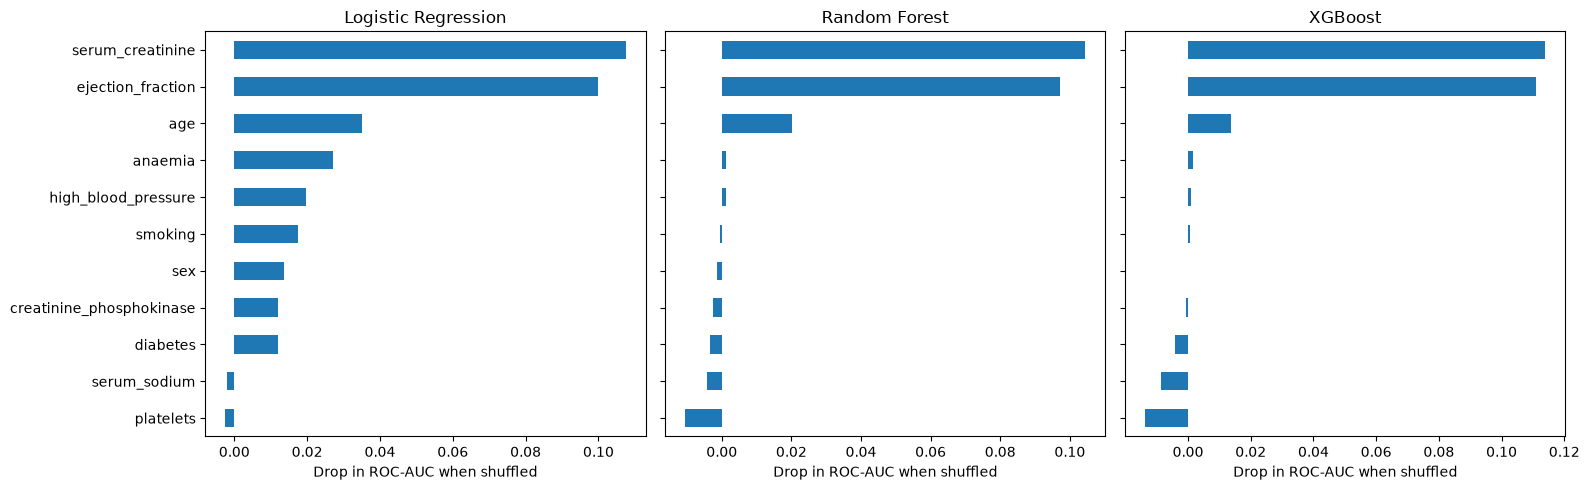

,Logistic Regression,Random Forest,XGBoost,average
time,0.2021,0.2338,0.2569,0.2309
ejection_fraction,0.0684,0.0497,0.0460,0.0547
serum_creatinine,0.0339,0.0489,0.0363,0.0397
creatinine_phosphokinase,0.0075,0.0073,0.0029,0.0059
age,0.0095,0.0014,0.0012,0.0040


,coefficient,odds_ratio_per_1_SD
serum_creatinine,1.089,2.972
ejection_fraction,-0.786,0.456
age,0.480,1.616
anaemia,0.352,1.421
creatinine_phosphokinase,0.349,1.417
high_blood_pressure,0.326,1.386
diabetes,0.290,1.336
smoking,0.225,1.252
serum_sodium,-0.182,0.833
platelets,-0.135,0.874


In [12]:
def cv_permutation_importance(model, cols, n_repeats=5):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    imps = []
    for tr, va in skf.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[tr][cols], y_train.iloc[tr])
        r = permutation_importance(m, X_train.iloc[va][cols], y_train.iloc[va],
                                   scoring='roc_auc', n_repeats=n_repeats,
                                   random_state=RANDOM_STATE)
        imps.append(r.importances_mean)
    return pd.Series(np.mean(imps, axis=0), index=cols)

MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost']
importance = {}
for fs_name, cols in FEATURE_SETS.items():
    importance[fs_name] = pd.DataFrame({
        m_name: cv_permutation_importance(best_models[(fs_name, m_name)], cols)
        for m_name in MODEL_NAMES
    })

# Without time (realistic version)
imp_no_time = importance['without time'].copy()
imp_no_time['average'] = imp_no_time.mean(axis=1)
imp_no_time = imp_no_time.sort_values('average', ascending=False)
display(imp_no_time.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for a, m_name in zip(ax, MODEL_NAMES):
    imp_no_time[m_name].sort_values().plot.barh(ax=a)
    a.set_title(m_name)
    a.set_xlabel('Drop in ROC-AUC when shuffled')
plt.tight_layout()
plt.show()

# With time: where does it rank?
imp_with_time = importance['with time'].copy()
imp_with_time['average'] = imp_with_time.mean(axis=1)
display(imp_with_time.sort_values('average', ascending=False).round(4).head(5))

# Logistic Regression odds ratios (without time)
lr = clone(best_models[('without time', 'Logistic Regression')]).fit(X_train[NO_TIME], y_train)
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=NO_TIME)
lr_table = pd.DataFrame({'coefficient': coef, 'odds_ratio_per_1_SD': np.exp(coef)})
lr_table.sort_values('coefficient', key=abs, ascending=False).round(3)

## Step 13: Final test on the 60 held-out patients
**Run this cell ONCE, then stop.** Do not change the models or settings after seeing these results. That would turn the test set into more training data and the score would no longer be honest.

Every model was chosen and tuned before this step. Here each one is trained on the full training set (real only, and real + synthetic) and scored on the 60 test patients.
Because 60 patients is small, the accuracy 95% CI column shows how uncertain the accuracy is.

**Result:** with `time`, test accuracy is 0.80 to 0.85. Without `time`: 0.683 (Logistic Regression), 0.717 (Random Forest), 0.767 (XGBoost), against a baseline of 0.683. Step 16 looks at the test set a second time to compare imbalance fixes. Nothing was chosen based on it.

,features,training data,model,accuracy,precision,recall,f1,roc_auc,accuracy 95% CI
0,any,real only,Majority-class baseline,0.683,0.000,0.000,0.000,0.500,
1,with time,real only,Logistic Regression,0.800,0.733,0.579,0.647,0.860,0.70 to 0.90
2,with time,real + synthetic,Logistic Regression,0.800,0.733,0.579,0.647,0.865,0.70 to 0.90
3,with time,real only,Random Forest,0.850,0.812,0.684,0.743,0.899,0.75 to 0.93
4,with time,real + synthetic,Random Forest,0.833,0.800,0.632,0.706,0.900,0.73 to 0.92
5,with time,real only,XGBoost,0.850,0.857,0.632,0.727,0.845,0.75 to 0.93
6,with time,real + synthetic,XGBoost,0.833,0.800,0.632,0.706,0.874,0.73 to 0.92
7,without time,real only,Logistic Regression,0.683,0.500,0.526,0.513,0.734,0.57 to 0.80
8,without time,real + synthetic,Logistic Regression,0.700,0.526,0.526,0.526,0.765,0.58 to 0.82
9,without time,real only,Random Forest,0.717,0.545,0.632,0.585,0.801,0.60 to 0.82


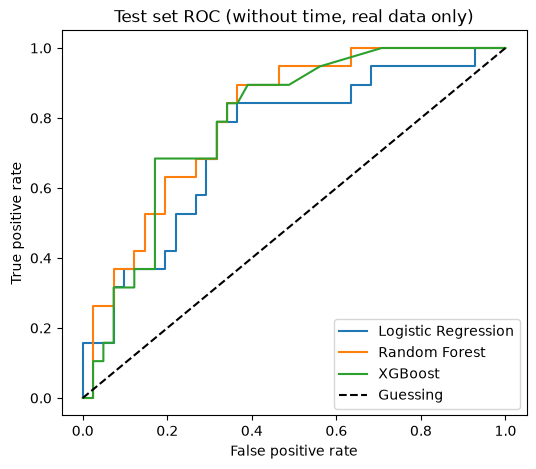

In [13]:
def evaluate_on_test(model, cols, use_synth):
    if use_synth:
        X_syn, y_syn = make_synthetic(X_train, y_train, seed=RANDOM_STATE)
        X_fit = pd.concat([X_train, X_syn], ignore_index=True)
        y_fit = pd.concat([y_train.reset_index(drop=True), y_syn], ignore_index=True)
    else:
        X_fit, y_fit = X_train, y_train
    m = fit_model(model, X_fit, y_fit, cols)
    pred = m.predict(X_test[cols])
    prob = m.predict_proba(X_test[cols])[:, 1]

    rng = np.random.default_rng(RANDOM_STATE)
    correct = (pred == y_test.values)
    boots = [correct[rng.integers(0, len(correct), len(correct))].mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])

    return {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
        'accuracy 95% CI': f"{lo:.2f} to {hi:.2f}",
    }, prob

final_rows, final_probs = [], {}

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
d_pred = dummy.predict(X_test)
final_rows.append({'features': 'any', 'training data': 'real only', 'model': 'Majority-class baseline',
                   'accuracy': accuracy_score(y_test, d_pred),
                   'precision': precision_score(y_test, d_pred, zero_division=0),
                   'recall': recall_score(y_test, d_pred), 'f1': f1_score(y_test, d_pred),
                   'roc_auc': 0.5, 'accuracy 95% CI': ''})

for (fs_name, m_name), model in best_models.items():
    for use_synth in (False, True):
        metrics, prob = evaluate_on_test(model, FEATURE_SETS[fs_name], use_synth)
        label = 'real + synthetic' if use_synth else 'real only'
        final_rows.append({'features': fs_name, 'training data': label, 'model': m_name, **metrics})
        final_probs[(fs_name, label, m_name)] = prob

final_table = pd.DataFrame(final_rows)
num_cols = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
final_table[num_cols] = final_table[num_cols].round(3)
display(final_table)

plt.figure(figsize=(6, 5))
for m_name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, final_probs[('without time', 'real only', m_name)])
    plt.plot(fpr, tpr, label=m_name)
plt.plot([0, 1], [0, 1], 'k--', label='Guessing')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Test set ROC (without time, real data only)')
plt.legend()
plt.show()

## Step 14: The professor's three focus areas
From here on, everything is **without `time`** (the realistic version), using the tuned models from Step 8.
1. **Imbalance** (Steps 15 to 17): only 32% of patients died. Does handling that help, and which fix is best?
2. **Without `time`** (Steps 15 to 17): a clean scoreboard, and proof the models beat guessing.
3. **Synthetic vs real** (Step 18): does adding artificial patients help, and why or why not?

**New terms.**
- **Recall:** of the patients who died, the share we caught.
- **Specificity:** of the patients who survived, the share we correctly called survivors.
- **Balanced accuracy:** the average of recall and specificity. Guessing "survived" for everyone scores 0.50.
- **PR-AUC:** like ROC-AUC but focused on the deaths. Guessing scores about 0.32 (the share who died).

**This cell is setup only. Run it first.** `SMOTE` is optional: it needs `pip install imbalanced-learn`, and the cells skip it if it is missing.

In [14]:
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, average_precision_score,
                             confusion_matrix, precision_recall_curve)

try:
    from imblearn.over_sampling import SMOTENC       # optional: pip install imbalanced-learn
    HAVE_SMOTE = True
except Exception:
    HAVE_SMOTE = False
print("SMOTE available:", HAVE_SMOTE)

MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost']

def all_metrics(y_true, pred, prob):
    """recall = share of deaths caught. specificity = share of survivors correctly called survivors."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'accuracy': (tp + tn) / (tp + tn + fp + fn),
        'balanced_acc': balanced_accuracy_score(y_true, pred),
        'recall': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'precision': tp / (tp + fp) if (tp + fp) > 0 else 0.0,
        'f1': f1_score(y_true, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, prob),
        'pr_auc': average_precision_score(y_true, prob),
    }

def unweighted(model):
    """Copy of a model with every class-weight setting switched off."""
    m = clone(model)
    p = m.get_params()
    if 'clf__class_weight' in p: m.set_params(clf__class_weight=None)
    if 'class_weight' in p: m.set_params(class_weight=None)
    if 'scale_pos_weight' in p: m.set_params(scale_pos_weight=1.0)
    return m

def fit_weighted(model, X_fit, y_fit, cols, weighted):
    m = unweighted(model)
    p = m.get_params()
    if weighted:
        if 'clf__class_weight' in p: m.set_params(clf__class_weight='balanced')
        if 'class_weight' in p: m.set_params(class_weight='balanced')
        if 'scale_pos_weight' in p:
            m.set_params(scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum())
    return m.fit(X_fit[cols], y_fit)

def jitter_rows(base, k, rng, sd, lo, hi, noise=0.10):
    """Same idea as Step 10: copy random real rows, add a small wiggle, stay inside the real range."""
    new = base.iloc[rng.integers(0, len(base), size=k)].reset_index(drop=True).copy()
    for col in CONT_COLS:
        new[col] = (new[col] + rng.normal(0, noise * sd[col], size=k)).clip(lo[col], hi[col])
    for col in INT_COLS:
        new[col] = new[col].round()
    return new

def resample_for_strategy(strategy, X_tr, y_tr, seed):
    """Returns (X_fit, y_fit, use_class_weights). Only ever sees TRAINING rows."""
    X_tr, y_tr = X_tr.reset_index(drop=True), y_tr.reset_index(drop=True)
    if strategy in ('no handling', 'threshold tuning'):
        return X_tr, y_tr, False
    if strategy == 'class weights':
        return X_tr, y_tr, True

    rng = np.random.default_rng(seed)
    need = int((y_tr == 0).sum() - (y_tr == 1).sum())        # how many extra deaths to reach 50/50
    pos_rows = X_tr[y_tr == 1]
    if strategy == 'random oversampling':                    # repeat real deaths
        extra = pos_rows.iloc[rng.integers(0, len(pos_rows), size=need)]
    elif strategy == 'synthetic minority':                   # artificial deaths from Step 10's recipe
        extra = jitter_rows(pos_rows, need, rng, X_tr[CONT_COLS].std(),
                            X_tr[CONT_COLS].min(), X_tr[CONT_COLS].max())
    elif strategy == 'SMOTE':                                # blend neighbouring real deaths
        cat_idx = [list(X_tr.columns).index(c) for c in BINARY_COLS]
        Xr, yr = SMOTENC(categorical_features=cat_idx, random_state=seed).fit_resample(X_tr, y_tr)
        return Xr.reset_index(drop=True), yr.reset_index(drop=True), False
    X_fit = pd.concat([X_tr, extra], ignore_index=True)
    y_fit = pd.concat([y_tr, pd.Series(np.ones(len(extra), dtype=int))], ignore_index=True)
    return X_fit, y_fit, False

def pick_cutoff(model, X_tr, y_tr, cols):
    """Choose the probability cut-off using TRAINING rows only (inner cross-validation).
    Goal: the cut-off that gives the best balanced accuracy (deaths and survivors count equally)."""
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    oof = cross_val_predict(unweighted(model), X_tr[cols], y_tr, cv=inner,
                            method='predict_proba')[:, 1]
    grid = np.linspace(0.05, 0.95, 91)
    scores = np.array([balanced_accuracy_score(y_tr, (oof >= t).astype(int)) for t in grid])
    return float(np.median(grid[scores >= scores.max() - 1e-12]))

def honest_ci(diffs, test_over_train=0.25):
    """95% range for an average difference across overlapping CV folds (Nadeau-Bengio correction).
    Wider than a plain t-interval, because repeated CV folds are not independent."""
    d = np.asarray(diffs, float)
    k = len(d)
    se = np.sqrt((1 / k + test_over_train) * d.var(ddof=1))
    t = stats.t.ppf(0.975, k - 1)
    return d.mean(), d.mean() - t * se, d.mean() + t * se

print("Setup done.")

SMOTE available: False
Setup done.


## Step 15: Imbalance, tested inside cross-validation (without `time`)
Only 32% of patients died, so a model can score decently by playing it safe and rarely predicting "died".
Here every model is trained five ways and scored on held-out real patients (training data only). SMOTE is also coded but was not run, because the optional package was not installed::
- **no handling:** ignore the imbalance.
- **class weights:** what we have used so far. Deaths count about twice as much.
- **random oversampling:** repeat real deaths until deaths and survivors are 50/50.
- **synthetic minority:** make artificial deaths (Step 10's recipe) until 50/50.
- **threshold tuning:** no weights. Instead, move the cut-off for saying "died" from 0.5 to a better value, chosen only on training data.
- **SMOTE** (optional): blend neighbouring real deaths to make new ones.

Everything is done **inside each fold, on training rows only**. The test set is not touched here.
**How to read it:** look at `recall` (deaths caught) vs `specificity` (survivors caught). The dashed line in the chart is the baseline accuracy (0.678).
The last table asks: is each model **clearly** better than guessing? (The "95% range" is wider than usual on purpose, because cross-validation folds overlap.)

,model,fix,accuracy,balanced_acc,recall,specificity,precision,f1,roc_auc,pr_auc
0,Majority-class baseline,-,0.678 ± 0.010,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.322 ± 0.010
1,Logistic Regression,no handling,0.741 ± 0.050,0.662 ± 0.063,0.442 ± 0.123,0.883 ± 0.051,0.652 ± 0.138,0.517 ± 0.112,0.788 ± 0.058,0.659 ± 0.075
2,Logistic Regression,class weights,0.760 ± 0.053,0.755 ± 0.050,0.740 ± 0.080,0.770 ± 0.075,0.612 ± 0.076,0.667 ± 0.061,0.794 ± 0.055,0.660 ± 0.083
3,Logistic Regression,random oversampling,0.749 ± 0.051,0.740 ± 0.050,0.715 ± 0.087,0.766 ± 0.072,0.599 ± 0.073,0.648 ± 0.061,0.790 ± 0.056,0.656 ± 0.083
4,Logistic Regression,synthetic minority,0.749 ± 0.054,0.741 ± 0.052,0.719 ± 0.086,0.763 ± 0.075,0.599 ± 0.076,0.650 ± 0.064,0.788 ± 0.056,0.654 ± 0.083
5,Logistic Regression,threshold tuning,0.736 ± 0.060,0.728 ± 0.068,0.705 ± 0.155,0.751 ± 0.098,0.585 ± 0.093,0.628 ± 0.100,0.788 ± 0.058,0.659 ± 0.075
6,Random Forest,no handling,0.750 ± 0.044,0.657 ± 0.051,0.395 ± 0.101,0.920 ± 0.049,0.718 ± 0.134,0.501 ± 0.092,0.791 ± 0.048,0.695 ± 0.069
7,Random Forest,class weights,0.760 ± 0.040,0.735 ± 0.050,0.663 ± 0.110,0.807 ± 0.057,0.624 ± 0.070,0.638 ± 0.068,0.784 ± 0.044,0.680 ± 0.065
8,Random Forest,random oversampling,0.754 ± 0.045,0.724 ± 0.054,0.640 ± 0.109,0.809 ± 0.058,0.618 ± 0.075,0.625 ± 0.075,0.774 ± 0.052,0.665 ± 0.065
9,Random Forest,synthetic minority,0.756 ± 0.048,0.726 ± 0.061,0.640 ± 0.115,0.811 ± 0.051,0.618 ± 0.073,0.625 ± 0.083,0.784 ± 0.045,0.680 ± 0.070


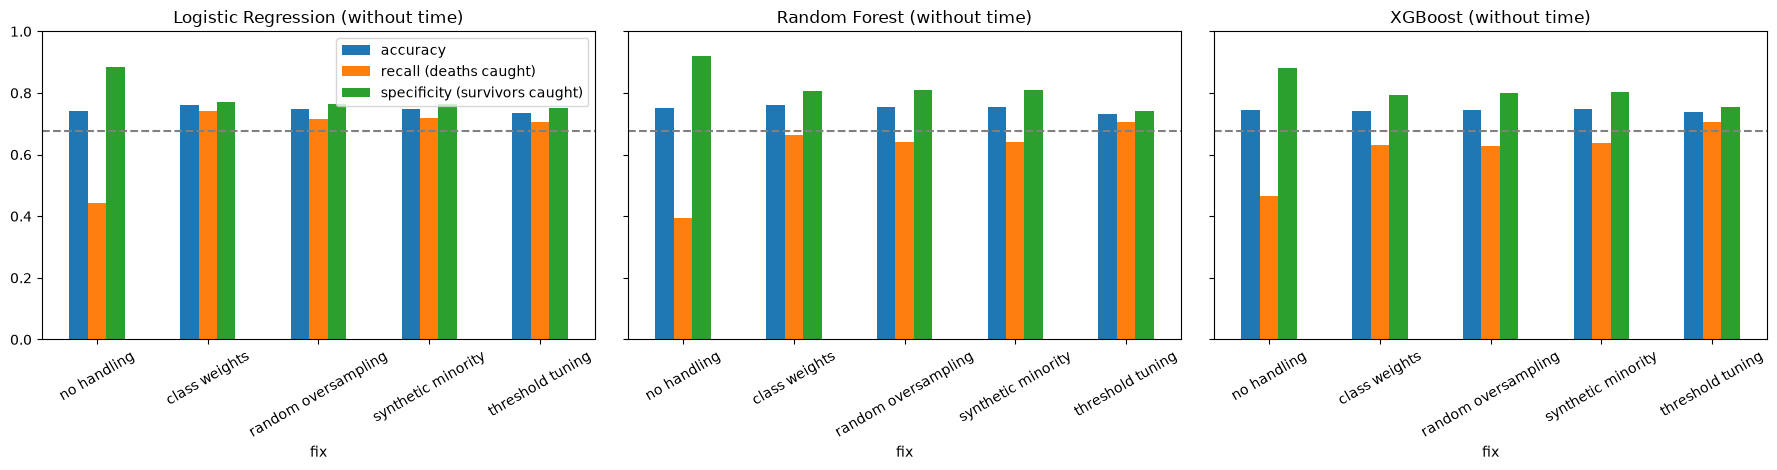

,model,metric,gain over guessing,95% range,clearly better than guessing?
0,Logistic Regression,accuracy,0.082,0.021 to 0.144,yes
1,Logistic Regression,balanced_acc,0.255,0.195 to 0.315,yes
2,Logistic Regression,roc_auc,0.294,0.228 to 0.360,yes
3,Random Forest,accuracy,0.082,0.033 to 0.131,yes
4,Random Forest,balanced_acc,0.235,0.175 to 0.295,yes
5,Random Forest,roc_auc,0.284,0.231 to 0.337,yes
6,XGBoost,accuracy,0.064,0.006 to 0.122,yes
7,XGBoost,balanced_acc,0.213,0.147 to 0.280,yes
8,XGBoost,roc_auc,0.269,0.196 to 0.343,yes


In [15]:
imb_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
IMB_STRATEGIES = ['no handling', 'class weights', 'random oversampling',
                  'synthetic minority', 'threshold tuning'] + (['SMOTE'] if HAVE_SMOTE else [])

def cv_strategy(model, cols, strategy):
    rows = []
    for fold, (tr, va) in enumerate(imb_cv.split(X_train, y_train)):
        X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
        X_va, y_va = X_train.iloc[va], y_train.iloc[va]
        cut = pick_cutoff(model, X_tr, y_tr, cols) if strategy == 'threshold tuning' else 0.5
        X_fit, y_fit, weighted = resample_for_strategy(strategy, X_tr, y_tr, RANDOM_STATE + fold)
        m = fit_weighted(model, X_fit, y_fit, cols, weighted)
        prob = m.predict_proba(X_va[cols])[:, 1]
        rows.append({**all_metrics(y_va, (prob >= cut).astype(int), prob), 'cutoff': cut})
    return pd.DataFrame(rows)

def cv_baseline(cols):
    rows = []
    for tr, va in imb_cv.split(X_train, y_train):
        d = DummyClassifier(strategy='most_frequent').fit(X_train.iloc[tr][cols], y_train.iloc[tr])
        prob = d.predict_proba(X_train.iloc[va][cols])[:, 1]
        rows.append(all_metrics(y_train.iloc[va], d.predict(X_train.iloc[va][cols]), prob))
    return pd.DataFrame(rows)

METRICS_SHOWN = ['accuracy', 'balanced_acc', 'recall', 'specificity', 'precision', 'f1', 'roc_auc', 'pr_auc']
def summarize(f):
    return {k: f"{f[k].mean():.3f} ± {f[k].std():.3f}" for k in METRICS_SHOWN}

base_folds = cv_baseline(NO_TIME)
imb_rows = [{'model': 'Majority-class baseline', 'fix': '-', **summarize(base_folds)}]
imb_fold_scores = {}
for m_name in MODEL_NAMES:
    model = best_models[('without time', m_name)]          # tuned models, WITHOUT time
    for strat in IMB_STRATEGIES:
        f = cv_strategy(model, NO_TIME, strat)
        imb_fold_scores[(m_name, strat)] = f
        imb_rows.append({'model': m_name, 'fix': strat, **summarize(f)})

imb_table = pd.DataFrame(imb_rows)
display(imb_table)

# Picture: what each fix trades. Dashed line = baseline accuracy (0.678).
mean_df = pd.DataFrame([{
    'model': m, 'fix': s, 'accuracy': f['accuracy'].mean(),
    'recall (deaths caught)': f['recall'].mean(),
    'specificity (survivors caught)': f['specificity'].mean()}
    for (m, s), f in imb_fold_scores.items()])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for a, m_name in zip(ax, MODEL_NAMES):
    d = mean_df[mean_df['model'] == m_name].set_index('fix').drop(columns='model')
    d.plot.bar(ax=a, rot=30, legend=(m_name == MODEL_NAMES[0]))
    a.axhline(base_folds['accuracy'].mean(), ls='--', c='gray')
    a.set_title(m_name + ' (without time)')
    a.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# Is each model clearly better than guessing "survived"? (class-weights version)
rows = []
for m_name in MODEL_NAMES:
    f = imb_fold_scores[(m_name, 'class weights')]
    for metric, ref in [('accuracy', base_folds['accuracy'].values),
                        ('balanced_acc', 0.5), ('roc_auc', 0.5)]:
        mean_d, lo, hi = honest_ci(f[metric].values - ref)
        rows.append({'model': m_name, 'metric': metric, 'gain over guessing': round(mean_d, 3),
                     '95% range': f"{lo:.3f} to {hi:.3f}",
                     'clearly better than guessing?': 'yes' if lo > 0 else 'no'})
display(pd.DataFrame(rows))

**What Step 15 shows (without `time`, cross-validation on training data only)**
- **Ignoring the imbalance misses deaths.** With no handling, the models caught only 44% (Logistic Regression), 40% (Random Forest), and 46% (XGBoost) of deaths.
- **Class weights raise deaths caught without hurting accuracy.** Deaths caught rose to 74%, 66%, and 63%. Accuracy stayed at 0.74 to 0.76.
- **The fixes are about equal.** Class weights, random oversampling, artificial deaths, and cut-off tuning all land at 63% to 74% recall and 0.71 to 0.76 balanced accuracy. The gaps are smaller than the fold-to-fold spread (about ±10 points on recall), so we do not claim a best fix.
- **All three models beat guessing.** The accuracy gain over the baseline is 0.064 to 0.082, and the 95% ranges stay above 0 (XGBoost's is borderline: 0.006 to 0.122).
- **The 80% goal is still not reached.** Imbalance handling changes which patients the model catches, not the ceiling.

## Step 16: Imbalance fixes on the 60 test patients (without `time`)
Same six approaches, now trained on all 239 training patients and scored on the 60 held-out patients.
**Important:** Step 13 already used the test set once, so this is a second look. **We do not pick a winner from this table.** We show every approach and choose nothing based on it.
With only 19 deaths in the test set, one patient changes recall by about 5 points, so small gaps between approaches are noise.

The matrices show what really happened (rows) vs what the model said (columns). The bottom-left box is **deaths the model missed**.

,model,fix,cutoff,accuracy,balanced_acc,recall,specificity,precision,f1,roc_auc,pr_auc
0,Majority-class baseline,-,-,0.683,0.500,0.000,1.000,0.000,0.000,0.500,0.317
1,Logistic Regression,no handling,0.5,0.700,0.611,0.368,0.854,0.538,0.438,0.745,0.599
2,Logistic Regression,class weights,0.5,0.683,0.641,0.526,0.756,0.500,0.513,0.734,0.591
3,Logistic Regression,random oversampling,0.5,0.683,0.641,0.526,0.756,0.500,0.513,0.764,0.622
4,Logistic Regression,synthetic minority,0.5,0.683,0.641,0.526,0.756,0.500,0.513,0.764,0.622
5,Logistic Regression,threshold tuning,0.31,0.700,0.668,0.579,0.756,0.524,0.550,0.745,0.599
6,Random Forest,no handling,0.5,0.733,0.635,0.368,0.902,0.636,0.467,0.793,0.614
7,Random Forest,class weights,0.5,0.717,0.694,0.632,0.756,0.545,0.585,0.801,0.606
8,Random Forest,random oversampling,0.5,0.767,0.730,0.632,0.829,0.632,0.632,0.779,0.597
9,Random Forest,synthetic minority,0.5,0.700,0.668,0.579,0.756,0.524,0.550,0.765,0.593


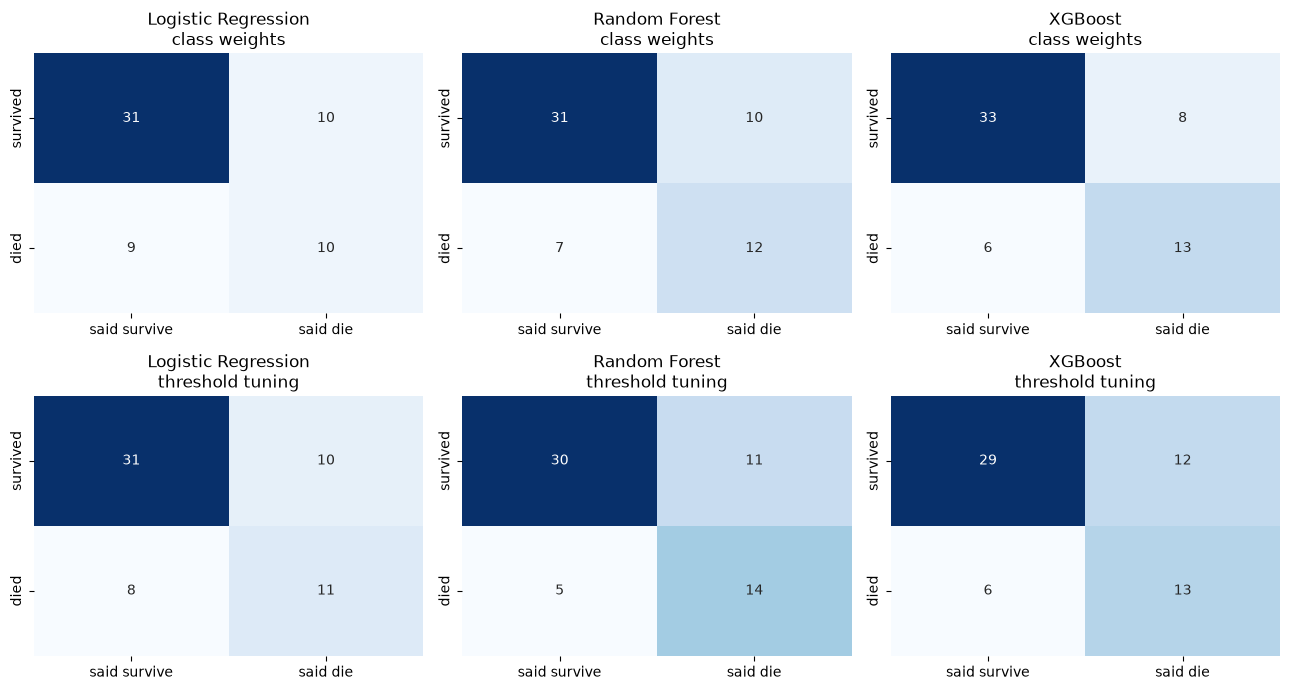

In [16]:
def fit_and_predict_test(model, strategy, seed=RANDOM_STATE):
    cut = pick_cutoff(model, X_train, y_train, NO_TIME) if strategy == 'threshold tuning' else 0.5
    X_fit, y_fit, weighted = resample_for_strategy(strategy, X_train, y_train, seed)
    m = fit_weighted(model, X_fit, y_fit, NO_TIME, weighted)
    prob = m.predict_proba(X_test[NO_TIME])[:, 1]
    return prob, (prob >= cut).astype(int), cut

base_pred = np.zeros(len(y_test), dtype=int)
base_r = all_metrics(y_test, base_pred, np.zeros(len(y_test)))
test_rows = [{'model': 'Majority-class baseline', 'fix': '-', 'cutoff': '-',
              **{k: round(v, 3) for k, v in base_r.items()}}]
test_store = {}
for m_name in MODEL_NAMES:
    for strat in IMB_STRATEGIES:
        prob, pred, cut = fit_and_predict_test(best_models[('without time', m_name)], strat)
        test_store[(m_name, strat)] = (prob, pred)
        r = all_metrics(y_test, pred, prob)
        test_rows.append({'model': m_name, 'fix': strat, 'cutoff': round(cut, 2),
                          **{k: round(v, 3) for k, v in r.items()}})
test_imb_table = pd.DataFrame(test_rows)
display(test_imb_table)

# Confusion matrices: rows = what really happened, columns = what the model said
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for j, m_name in enumerate(MODEL_NAMES):
    for i, strat in enumerate(['class weights', 'threshold tuning']):
        pred = test_store[(m_name, strat)][1]
        cm = confusion_matrix(y_test, pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cbar=False, ax=ax[i, j], cmap='Blues',
                    xticklabels=['said survive', 'said die'], yticklabels=['survived', 'died'])
        ax[i, j].set_title(f"{m_name}\n{strat}")
plt.tight_layout()
plt.show()

**What Step 16 shows (60 test patients, 19 deaths)**
- With no handling, every model caught only 7 of 19 deaths.
- With class weights, they caught 10 (Logistic Regression), 12 (Random Forest), and 13 (XGBoost).
- Test accuracy did not rise for two models (Logistic Regression 0.700 → 0.683, Random Forest 0.733 → 0.717; XGBoost 0.733 → 0.767), so the gain is in deaths caught, not accuracy.
- Gaps between the fixes are 1 to 3 patients, which is noise. We pick no winner.

## Step 17: Without `time` scoreboard, with uncertainty
The one table to show for the realistic version: test-set results for the three models (class-weights version, which is our main approach) next to the baseline.
The "95% range" columns come from re-sampling the 60 test patients 2,000 times. They show how much each score could move by luck.
If a range for ROC-AUC stays well above 0.50, the model ranks patients better than guessing, even with only 60 test patients.

,model,accuracy,accuracy 95% range,balanced_acc,recall,recall 95% range,roc_auc,pr_auc,roc_auc 95% range
0,Majority-class baseline,0.683,,0.500,0.000,,0.500,0.317,
1,Logistic Regression,0.683,0.57 to 0.80,0.641,0.526,0.29 to 0.76,0.734,0.591,0.59 to 0.87
2,Random Forest,0.717,0.60 to 0.82,0.694,0.632,0.41 to 0.85,0.801,0.606,0.67 to 0.90
3,XGBoost,0.767,0.65 to 0.87,0.745,0.684,0.47 to 0.88,0.791,0.566,0.67 to 0.89


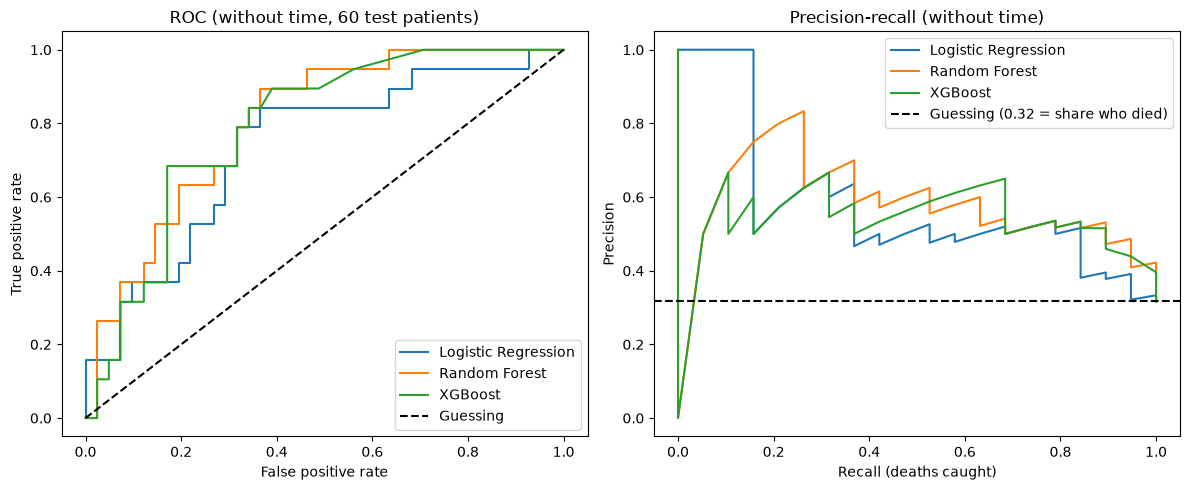

In [19]:
def boot_ci(y_true, prob, pred, n=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y = np.asarray(y_true)
    keys = ['accuracy', 'balanced_acc', 'recall', 'roc_auc', 'pr_auc']
    out = {k: [] for k in keys}
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        r = all_metrics(y[idx], pred[idx], prob[idx])
        for k in keys:
            out[k].append(r[k])
    return {k: f"{np.percentile(v, 2.5):.2f} to {np.percentile(v, 97.5):.2f}" for k, v in out.items()}

prevalence = y_test.mean()
rows = [{'model': 'Majority-class baseline', 'accuracy': round(base_r['accuracy'], 3), 'accuracy 95% range': '',
         'balanced_acc': 0.5, 'recall': 0.0, 'recall 95% range': '',
         'roc_auc': 0.5, 'pr_auc': round(prevalence, 3), 'roc_auc 95% range': ''}]
for m_name in MODEL_NAMES:
    prob, pred = test_store[(m_name, 'class weights')]
    r = all_metrics(y_test, pred, prob)
    ci = boot_ci(y_test, prob, pred)
    rows.append({'model': m_name, 'accuracy': round(r['accuracy'], 3), 'accuracy 95% range': ci['accuracy'],
                 'balanced_acc': round(r['balanced_acc'], 3), 'recall': round(r['recall'], 3),
                 'recall 95% range': ci['recall'], 'roc_auc': round(r['roc_auc'], 3),
                 'pr_auc': round(r['pr_auc'], 3), 'roc_auc 95% range': ci['roc_auc']})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for m_name in MODEL_NAMES:
    prob = test_store[(m_name, 'class weights')][0]
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=m_name)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(rec, prec, label=m_name)
ax[0].plot([0, 1], [0, 1], 'k--', label='Guessing')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC (without time, 60 test patients)'); ax[0].legend()
ax[1].axhline(prevalence, color='k', ls='--', label=f'Guessing ({prevalence:.2f} = share who died)')
ax[1].set_xlabel('Recall (deaths caught)'); ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-recall (without time)'); ax[1].legend()
plt.tight_layout()
plt.show()

**What Step 17 shows (without `time`, 60 test patients, class-weights models)**
- ROC-AUC is 0.73 to 0.80 (95% ranges roughly 0.59 to 0.90), well above the 0.50 of guessing.
- Accuracy ranges include the 0.683 baseline (XGBoost: 0.65 to 0.87), so the test set alone cannot show higher accuracy than guessing. Cross-validation (Step 15) is the stronger evidence.
- Deaths caught: 10, 12, and 13 of 19.

## Step 18: Synthetic vs non-synthetic (without `time`)
Four checks on whether the 1,000 artificial records help:
- **(a) Same folds, with vs without artificial records.** The "95% range for change" says whether the difference is real. If the range includes 0, it is not.
- **(b) Does more help?** We try 0, 250, 500, 1,000, and 2,000 artificial records.
- **(c) Why?** We measure how close the artificial records are to real training patients, compared with how close brand-new real patients are.
- **(d) Test set.** The same comparison on the 60 test patients, from Step 13 (nothing re-run).

In every check, the artificial records are made from **training rows only** and the evaluation is on **real patients only**.

,model,metric,real only,real + synthetic,change,95% range for change,real difference?
0,Logistic Regression,accuracy,0.752,0.751,-0.001,-0.044 to 0.043,no
1,Logistic Regression,recall,0.728,0.718,-0.009,-0.098 to 0.079,no
2,Logistic Regression,roc_auc,0.791,0.786,-0.005,-0.031 to 0.020,no
3,Random Forest,accuracy,0.765,0.764,-0.001,-0.037 to 0.036,no
4,Random Forest,recall,0.676,0.660,-0.016,-0.076 to 0.045,no
5,Random Forest,roc_auc,0.790,0.782,-0.008,-0.036 to 0.019,no
6,XGBoost,accuracy,0.747,0.754,0.008,-0.015 to 0.030,no
7,XGBoost,recall,0.642,0.671,0.029,-0.019 to 0.077,no
8,XGBoost,roc_auc,0.779,0.780,0.001,-0.032 to 0.034,no


,model,synthetic records,accuracy,recall,roc_auc
0,Logistic Regression,0,0.760,0.740,0.794
1,Logistic Regression,250,0.751,0.720,0.780
2,Logistic Regression,500,0.743,0.707,0.782
3,Logistic Regression,1000,0.750,0.720,0.785
4,Logistic Regression,2000,0.746,0.728,0.793
5,Random Forest,0,0.760,0.663,0.784
6,Random Forest,250,0.745,0.616,0.774
7,Random Forest,500,0.752,0.628,0.778
8,Random Forest,1000,0.761,0.650,0.776
9,Random Forest,2000,0.756,0.663,0.777


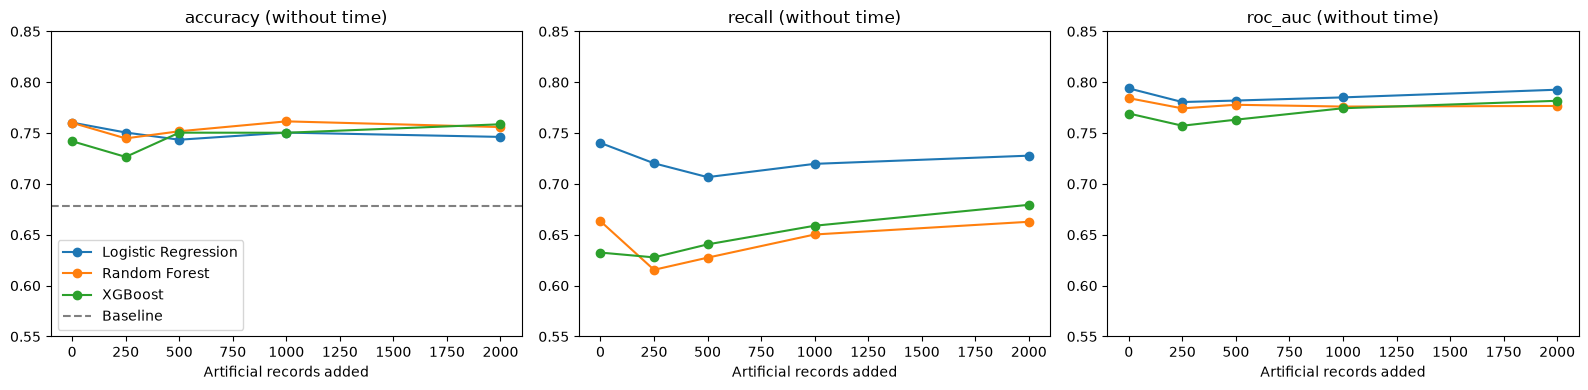

Median distance to the nearest REAL training patient (smaller = more similar):
  artificial records:                0.24
  real training patients (to others): 1.56
  brand-new real test patients:       1.48


,model,acc real only,acc real+synth,recall real only,recall real+synth,AUC real only,AUC real+synth
0,Logistic Regression,0.683,0.700,0.526,0.526,0.734,0.765
1,Random Forest,0.717,0.717,0.632,0.632,0.801,0.787
2,XGBoost,0.767,0.750,0.684,0.684,0.791,0.789


In [17]:
# (a) Paired comparison inside cross-validation, WITHOUT time
rows = []
for m_name in MODEL_NAMES:
    model = best_models[('without time', m_name)]
    real = cv_real_vs_synth(model, NO_TIME, use_synth=False)
    synth = cv_real_vs_synth(model, NO_TIME, use_synth=True)
    for metric in ['accuracy', 'recall', 'roc_auc']:
        mean_d, lo, hi = honest_ci(synth[metric] - real[metric])
        rows.append({'model': m_name, 'metric': metric,
                     'real only': round(real[metric].mean(), 3),
                     'real + synthetic': round(synth[metric].mean(), 3),
                     'change': round(mean_d, 3), '95% range for change': f"{lo:.3f} to {hi:.3f}",
                     'real difference?': 'yes' if (lo > 0 or hi < 0) else 'no'})
display(pd.DataFrame(rows))

# (b) Does MORE synthetic data help? (0, 250, 500, 1000, 2000 artificial records)
dose_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
SIZES = [0, 250, 500, 1000, 2000]
dose_rows = []
for m_name in MODEL_NAMES:
    model = best_models[('without time', m_name)]
    for n_syn in SIZES:
        accs, recs, aucs = [], [], []
        for fold, (tr, va) in enumerate(dose_cv.split(X_train, y_train)):
            X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
            X_va, y_va = X_train.iloc[va], y_train.iloc[va]
            if n_syn > 0:
                X_syn, y_syn = make_synthetic(X_tr, y_tr, n=n_syn, seed=RANDOM_STATE + fold)
                X_fit = pd.concat([X_tr, X_syn], ignore_index=True)
                y_fit = pd.concat([y_tr.reset_index(drop=True), y_syn], ignore_index=True)
            else:
                X_fit, y_fit = X_tr, y_tr
            m = fit_model(model, X_fit, y_fit, NO_TIME)
            prob = m.predict_proba(X_va[NO_TIME])[:, 1]
            r = all_metrics(y_va, (prob >= 0.5).astype(int), prob)
            accs.append(r['accuracy']); recs.append(r['recall']); aucs.append(r['roc_auc'])
        dose_rows.append({'model': m_name, 'synthetic records': n_syn,
                          'accuracy': np.mean(accs), 'recall': np.mean(recs), 'roc_auc': np.mean(aucs)})
dose_df = pd.DataFrame(dose_rows)
display(dose_df.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, metric in zip(ax, ['accuracy', 'recall', 'roc_auc']):
    for m_name in MODEL_NAMES:
        d = dose_df[dose_df['model'] == m_name]
        a.plot(d['synthetic records'], d[metric], marker='o', label=m_name)
    a.set_xlabel('Artificial records added'); a.set_title(metric + ' (without time)')
    a.set_ylim(0.55, 0.85)          # same scale for all three, so small wiggles are not exaggerated
ax[0].axhline(base_folds['accuracy'].mean(), ls='--', c='gray', label='Baseline')
ax[0].legend()
plt.tight_layout()
plt.show()

# (c) Why? Are the artificial records really new patients, or near-copies?
scaler = StandardScaler().fit(X_train[NO_TIME])
Z_real = scaler.transform(X_train[NO_TIME])
nn = NearestNeighbors(n_neighbors=2).fit(Z_real)
d_synth = nn.kneighbors(scaler.transform(X_syn_demo[NO_TIME]), n_neighbors=1)[0].ravel()
d_real = nn.kneighbors(Z_real, n_neighbors=2)[0][:, 1]            # nearest OTHER real patient
d_test = nn.kneighbors(scaler.transform(X_test[NO_TIME]), n_neighbors=1)[0].ravel()
print("Median distance to the nearest REAL training patient (smaller = more similar):")
print(f"  artificial records:                {np.median(d_synth):.2f}")
print(f"  real training patients (to others): {np.median(d_real):.2f}")
print(f"  brand-new real test patients:       {np.median(d_test):.2f}")

# (d) The same comparison on the 60 test patients (uses Step 13 results, nothing re-run)
ft = final_table[final_table['features'] == 'without time']
rows = []
for m_name in MODEL_NAMES:
    a = ft[(ft['model'] == m_name) & (ft['training data'] == 'real only')].iloc[0]
    b = ft[(ft['model'] == m_name) & (ft['training data'] == 'real + synthetic')].iloc[0]
    rows.append({'model': m_name,
                 'acc real only': a['accuracy'], 'acc real+synth': b['accuracy'],
                 'recall real only': a['recall'], 'recall real+synth': b['recall'],
                 'AUC real only': a['roc_auc'], 'AUC real+synth': b['roc_auc']})
display(pd.DataFrame(rows))

**What Step 18 shows (without `time`)**
- **Cross-validation:** none of the 9 comparisons has a 95% range that excludes 0. The artificial records made no real difference.
- **More records:** Logistic Regression and Random Forest stay flat (within about 2 points of the 0-record score at every size). XGBoost drifts up at 2,000 records (accuracy 0.742 → 0.759, recall 0.632 → 0.679), but that is inside the fold-to-fold spread, and the other two models don't move.
- **Why:** artificial records sit 0.24 from a real training patient, versus 1.48 for brand-new real patients, about 6 times closer. They are near-copies and add little new information.
- **Test set:** accuracy changed by at most 1 patient and recall did not change.

## Step 19: Answers to the professor's three questions
**1. Synthetic vs non-synthetic (without `time`).**
- Cross-validation: no. None of the 95% ranges for the change excludes 0.
- More artificial records: no consistent gain. Logistic Regression and Random Forest stay flat. XGBoost drifts up slightly at 2,000 records, within the fold-to-fold spread.
- Why: artificial records are about 6 times closer to training patients than brand-new real patients are (0.24 vs 1.48), so they are near-copies and add little new information.
- Test set: accuracy changed by at most 1 patient (Logistic Regression 0.683 → 0.700, Random Forest unchanged, XGBoost 0.767 → 0.750). Recall did not change.
- Answer: **did not help.**

**2. Without `time`.**
- Best test accuracy: XGBoost, 0.767 (95% range 0.65 to 0.87). Best tuned cross-validation accuracy: Random Forest, 0.763 ± 0.049. **The 80% goal was not reached.**
- Beats guessing? In cross-validation, yes: accuracy is 0.064 to 0.082 above the baseline with 95% ranges above 0, and balanced accuracy and ROC-AUC are clearly above 0.50. On the test set, ROC-AUC is 0.73 to 0.80 vs 0.50, but the accuracy ranges include the 0.683 baseline.
- Deaths caught on the test set: 13 of 19 (XGBoost), 12 (Random Forest), 10 (Logistic Regression).

**3. Imbalance.**
- With no handling, recall (deaths caught) was 0.44, 0.40, and 0.46 in cross-validation. With class weights it rose to 0.74, 0.66, and 0.63.
- Accuracy changed by +0.019, +0.010, and -0.004, so the fix did not cost accuracy.
- Class weights, random oversampling, artificial deaths, and cut-off tuning performed about the same (recall 0.63 to 0.74). SMOTE was not run.
- On the test set, no handling caught 7 of 19 deaths in every model. Class weights caught 10, 12, and 13.
- The 80% goal is still not reached because imbalance is not the only limit. With 299 patients and no `time`, the signal is modest.

## Wrap up
- **Baseline:** guessing "survived" gives about 68% accuracy (0.678 in cross-validation, 0.683 on the test set) and catches no deaths.
- **With `time`:** Random Forest was best (0.841 ± 0.043 tuned, 0.850 on the test set). This is an upper limit because `time` is not known when predicting for a new patient.
- **Without `time` (realistic):** no model reached 80%. Tuned cross-validation: Random Forest 0.763 ± 0.049, XGBoost 0.752 ± 0.046, Logistic Regression 0.745 ± 0.060. Test set: XGBoost 0.767, Random Forest 0.717, Logistic Regression 0.683 (baseline 0.683).
- **Tuning:** changed little. Without `time` it added up to 1.6 points, which is small next to the ±5 point spread between folds.
- **Imbalance:** class weights raised the share of deaths caught from about 40 to 46% to about 63 to 74% with no loss in accuracy. The different fixes performed about the same.
- **Synthetic data:** no real difference on real held-out patients. The artificial records are near-copies of training patients.
- **Most important features:** serum creatinine and ejection fraction, with age a distant third.
- **Limits:** only 299 real patients from one study, and a 60-patient test set (19 deaths) gives wide ranges on every score. Not ready for clinical use.

## Conclusion

- This project tested whether clinical measurements can predict death during follow-up in patients with heart failure. A baseline that always guesses "survived" scores about 68% accuracy and catches no deaths, so accuracy alone is not enough. With follow-up time included, Random Forest and XGBoost reached about 84% (85% on the test set). That is not a realistic setting, because follow-up time ends when a patient dies and is not known in advance. Without it, no model reached our 80% goal. The best tuned cross-validation accuracy was 0.763 (Random Forest) and the best test accuracy was 0.767 (XGBoost), compared with baselines of 0.678 and 0.683. In cross-validation, all three models were clearly better than guessing, but the gain is modest.

- Because only 32% of patients died, we tested the imbalance directly. With no handling, the models caught only about 40 to 46% of deaths. Class weights, oversampling, artificial deaths, and cut-off tuning raised that to about 63 to 74% without lowering accuracy, and they performed about the same as each other. Tuning the model settings changed little (up to 1.6 points). Artificial records made no real difference on real held-out patients, and a distance check showed why: they sit about six times closer to a training patient than a brand-new real patient does, so they are near-copies that add little new information. The most important predictors were serum creatinine and ejection fraction, which agrees with earlier published work on this dataset and with medical understanding of heart failure.

- Overall, the models find a real but modest signal. The limits are the small sample (299 patients from one study) and a 60-patient test set with 19 deaths, where one patient moves accuracy by about 1.7 points and the accuracy range for the best model (0.65 to 0.87) still includes the baseline. The test set was looked at twice (Steps 13 and 16), and nothing was chosen based on it. The models are not ready for clinical use. Future work should use larger, multi-center data and external validation.

